# EDA Awal — Dataset CIC DDoS 2017
**File:** `Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv`

- **Sumber:** Canadian Institute for Cybersecurity (CIC) — Friday afternoon working hours, network traffic hasil simulasi DDoS
- **Isi:** flow jaringan (225.745 baris × 85 kolom) dengan label `BENIGN` (normal) dan `DDoS`
- **Tujuan notebook ini:** memahami struktur data, kualitas data, distribusi kelas, karakteristik fitur, dan korelasi fitur terhadap label sebagai bekal preprocessing & pemodelan

> Dataset ini berasal dari file CSV yang sama seperti sebelumnya (dataset per row 73 MB), jadi library `pandas` cukup untuk memuatnya.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="Set2")

RANDOM_STATE = 42
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 2.3.3 | numpy 2.3.4 | seaborn 0.13.2


## 1. Load Dataset

In [2]:
df = pd.read_csv("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")
print("Shape:", df.shape)
df.head(3)

Shape: (225745, 85)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,12,0,6,6,6.00,0.00,0,0,0.00,0.00,"4,000,000.00","666,666.67",3.00,0.00,3,3,3,3.00,0.00,3,3,0,0.00,0.00,0,0,0,0,0,0,40,0,"666,666.67",0.00,6,6,6.00,0.00,0.00,0,0,0,0,1,0,0,0,0,9.00,6.00,0.00,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.00,0.00,0,0,0.00,0.00,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,6,6,6,6,6.00,0.00,6,6,6.00,0.00,"110,091.74","18,348.62",109.00,0.00,109,109,0,0.00,0.00,0,0,0,0.00,0.00,0,0,0,0,0,0,20,20,"9,174.31","9,174.31",6,6,6.00,0.00,0.00,0,0,0,0,1,1,0,0,1,9.00,6.00,6.00,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.00,0.00,0,0,0.00,0.00,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,6,6,6,6,6.00,0.00,6,6,6.00,0.00,"230,769.23","38,461.54",52.00,0.00,52,52,0,0.00,0.00,0,0,0,0.00,0.00,0,0,0,0,0,0,20,20,"19,230.77","19,230.77",6,6,6.00,0.00,0.00,0,0,0,0,1,1,0,0,1,9.00,6.00,6.00,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.00,0.00,0,0,0.00,0.00,0,0,BENIGN


## 2. Struktur & Kualitas Data

In [3]:
# Masalah kualitas data yang umum di dataset CIC:
# 1. spasi di nama kolom, 2. nama kolom duplikat, 3. baris duplikat, 4. nilai Infinity
print("Nama kolom ber-spasi awal :", sum(c != c.strip() for c in df.columns))
print("Nama kolom duplikat       :", df.columns.duplicated().sum())
print("Baris duplikat            :", df.duplicated().sum())
print("Label mentah              :", df[" Label"].unique(), "\n")

print("Distribusi tipe data:")
print(df.dtypes.value_counts(), "\n")

obj_cols = df.select_dtypes(include="object").columns.tolist()
print("Kolom kategorikal:", obj_cols)

Nama kolom ber-spasi awal : 70
Nama kolom duplikat       : 0


Baris duplikat            : 2
Label mentah              : ['BENIGN' 'DDoS'] 

Distribusi tipe data:
int64      56
float64    24
object      5
Name: count, dtype: int64 

Kolom kategorikal: ['Flow ID', ' Source IP', ' Destination IP', ' Timestamp', ' Label']


## 3. Pembersihan Awal
- Rapikan nama kolom (buang spasi, hapus kolom duplikat `Fwd Header Length`)
- `Infinity` pada `Flow Bytes/s` & `Flow Packets/s` → `NaN`
- Label distrip spasi, buang baris duplikat

In [4]:
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]          # buang kolom duplikat
df["Label"] = df["Label"].str.strip()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.drop_duplicates()

print("Shape setelah dibersihkan:", df.shape)
print("NaN per kolom (yang > 0):")
print(df.isna().sum()[lambda s: s > 0], "\n")

df.info()
print()
print(df["Label"].value_counts())

Shape setelah dibersihkan: (225743, 85)
NaN per kolom (yang > 0):


Flow Bytes/s      34
Flow Packets/s    34
dtype: int64 



<class 'pandas.core.frame.DataFrame'>
Index: 225743 entries, 0 to 225744
Data columns (total 85 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Flow ID                      225743 non-null  object 
 1   Source IP                    225743 non-null  object 
 2   Source Port                  225743 non-null  int64  
 3   Destination IP               225743 non-null  object 
 4   Destination Port             225743 non-null  int64  
 5   Protocol                     225743 non-null  int64  
 6   Timestamp                    225743 non-null  object 
 7   Flow Duration                225743 non-null  int64  
 8   Total Fwd Packets            225743 non-null  int64  
 9   Total Backward Packets       225743 non-null  int64  
 10  Total Length of Fwd Packets  225743 non-null  int64  
 11  Total Length of Bwd Packets  225743 non-null  int64  
 12  Fwd Packet Length Max        225743 non-null  int64  
 13  Fwd 

## 4. Distribusi Kelas

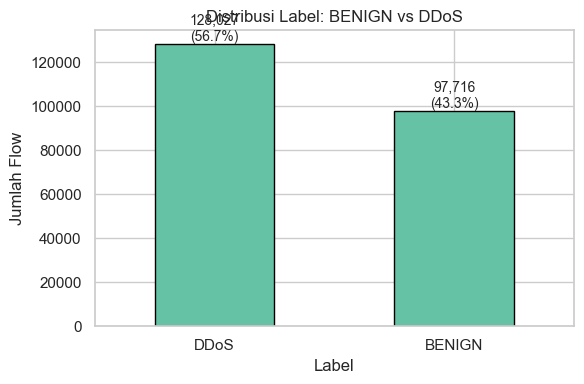

In [5]:
vc = df["Label"].value_counts()
pct = (vc / len(df) * 100).round(1)

ax = vc.plot(kind="bar", figsize=(6, 4), edgecolor="black")
for i, (v, p) in enumerate(zip(vc, pct)):
    ax.text(i, v + 1500, f"{v:,}\n({p}%)", ha="center", fontsize=10)
ax.set_title("Distribusi Label: BENIGN vs DDoS")
ax.set_xlabel("Label")
ax.set_ylabel("Jumlah Flow")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Statistik Deskriptif
Ringkasan 80 fitur numerik — divisualisasikan terpotong untuk fitur paling informatif.

In [6]:
desc = df.describe().T
desc

,count,mean,std,min,25%,50%,75%,max
Source Port,"225,743.00","38,257.43","23,057.36",0.00,"18,989.50","49,799.00","58,296.00","65,534.00"
Destination Port,"225,743.00","8,879.58","19,754.72",0.00,80.00,80.00,80.00,"65,532.00"
Protocol,"225,743.00",7.60,3.88,0.00,6.00,6.00,6.00,17.00
Flow Duration,"225,743.00","16,241,792.42","31,524,476.81",-1.00,"71,182.00","1,452,338.00","8,805,241.00","119,999,937.00"
Total Fwd Packets,"225,743.00",4.87,15.42,1.00,2.00,3.00,5.00,"1,932.00"
...,...,...,...,...,...,...,...,...
Active Min,"225,743.00","177,621.66","784,263.52",0.00,0.00,0.00,"1,862.00","100,000,000.00"
Idle Mean,"225,743.00","10,322,234.87","21,853,103.36",0.00,0.00,0.00,"8,239,739.50","120,000,000.00"
Idle Std,"225,743.00","3,611,974.93","12,756,945.44",0.00,0.00,0.00,0.00,"65,300,000.00"
Idle Max,"225,743.00","12,878,243.04","26,921,355.61",0.00,0.00,0.00,"8,253,853.50","120,000,000.00"


## 6. Distribusi Fitur Kunci per Kelas
Empat fitur yang paling membedakan BENIGN vs DDoS (berdasarkan korelasi, lihat bagian 7).

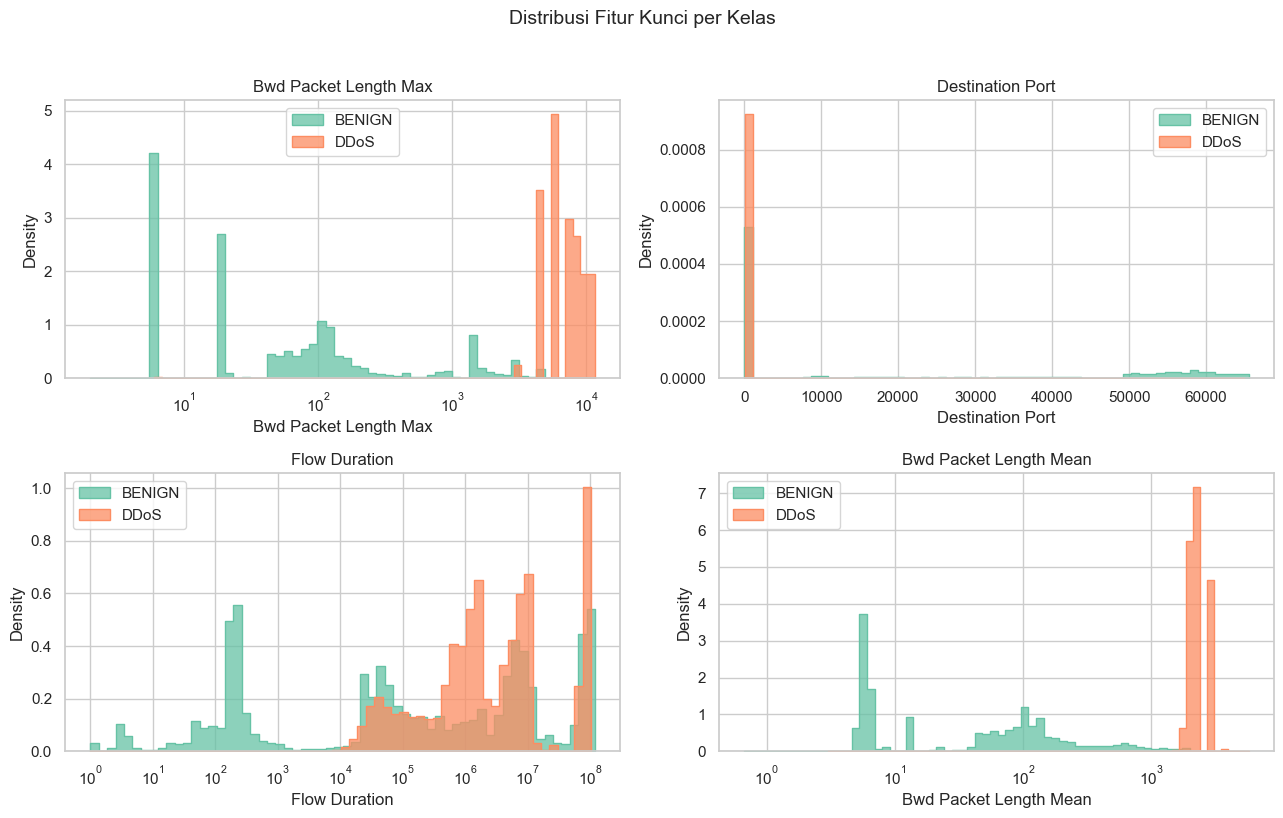

In [7]:
key_feats = ["Bwd Packet Length Max", "Destination Port", "Flow Duration", "Bwd Packet Length Mean"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col in zip(axes.ravel(), key_feats):
    for label, color in zip(["BENIGN", "DDoS"], ["#66c2a5", "#fc8d62"]):
        data = df.loc[df["Label"] == label, col]
        sns.histplot(data, bins=60, ax=ax, color=color, label=label,
                     log_scale=(col != "Destination Port"), element="step", stat="density", common_norm=False)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribusi Fitur Kunci per Kelas", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 7. Korelasi Fitur terhadap Label

C:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


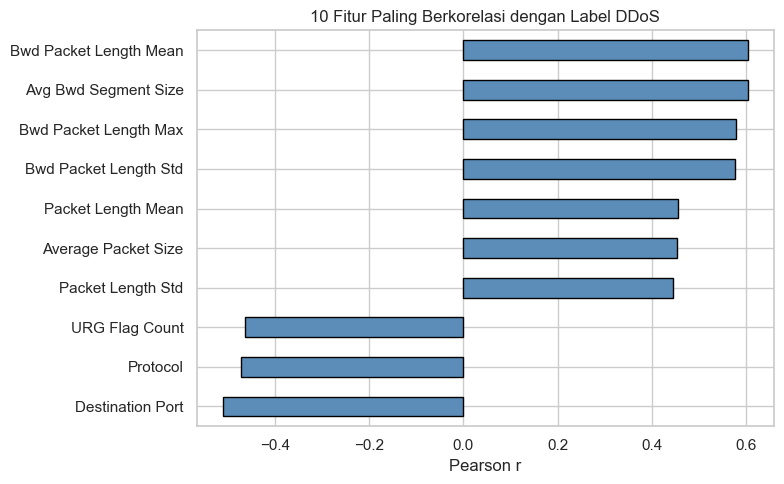

Korelasi positif (mengarah ke DDoS):
Bwd Packet Length Mean   0.60
Avg Bwd Segment Size     0.60
Bwd Packet Length Max    0.58
Bwd Packet Length Std    0.58
Packet Length Mean       0.45
dtype: float64 

Korelasi negatif (mengarah ke BENIGN):
Subflow Fwd Packets   -0.03
ECE Flag Count        -0.01
RST Flag Count        -0.01
Active Max            -0.01
act_data_pkt_fwd      -0.00
dtype: float64


In [8]:
df["is_ddos"] = (df["Label"] == "DDoS").astype(int)

num = df.select_dtypes(include=[np.number])
corr = num.corrwith(df["is_ddos"]).drop("is_ddos").sort_values(key=abs, ascending=False)

top = corr.head(10)
ax = top.sort_values().plot(kind="barh", figsize=(8, 5), edgecolor="black", color="#5b8db8")
ax.set_title("10 Fitur Paling Berkorelasi dengan Label DDoS")
ax.set_xlabel("Pearson r")
plt.tight_layout()
plt.show()

print("Korelasi positif (mengarah ke DDoS):")
print(corr[corr > 0].head(5).round(3), "\n")
print("Korelasi negatif (mengarah ke BENIGN):")
print(corr[corr < 0].tail(5).round(3))

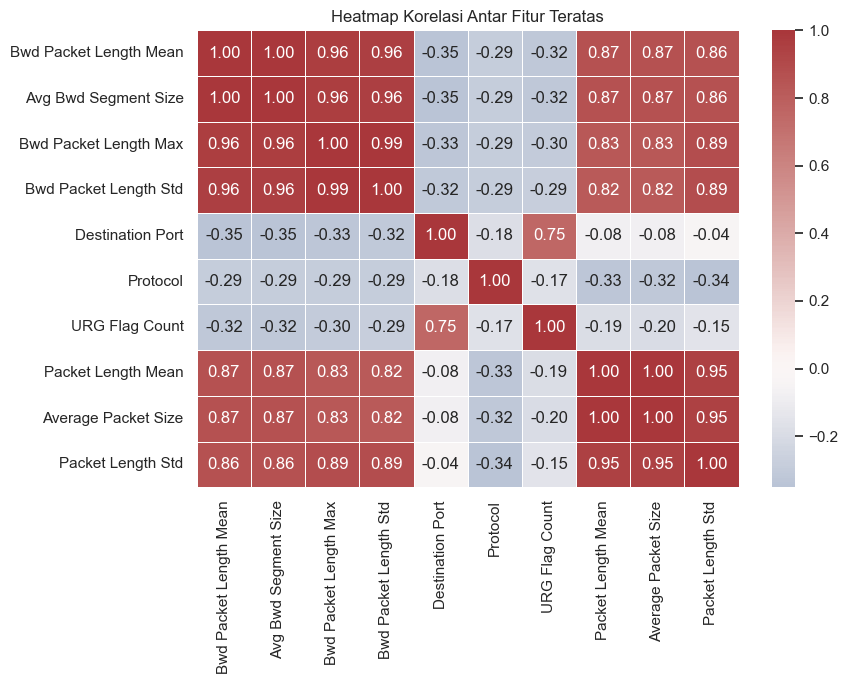

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(num[top.index].corr(), cmap="vlag", center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Fitur Teratas")
plt.tight_layout()
plt.show()

## 8. Ringkasan Temuan

1. **Ukuran data:** 225.743 baris × 85 kolom setelah dibersihkan (2 baris duplikat dibuang).
2. **Kelas hampir seimbang** — DDoS 128.027 (56,7%) vs BENIGN 97.718 (43,3%), jadi *class imbalance* bukan masalah utama di subset ini.
3. **Kualitas data:** hanya 34 nilai `Infinity` dan 4 `NaN` — sangat sedikit dibanding total baris; nama kolom perlu distrip.
4. **Fitur pembeda terkuat:** `Bwd Packet Length Mean/Max/Std` dan `Avg Bwd Segment Size` (r ≈ 0,58–0,60) — trafik DDoS punya pola panjang paket belakang yang khas; lalu `Destination Port` (r ≈ 0,51) dan `Protocol`.
5. **Multikolinearitas tinggi** di antara fitur statistik Bwd (heatmap) → saat pemodelan perlu dipertimbangkan dropping/PCA.
6. **Langkah berikutnya:** drop kolom identitas (`Flow ID`, `Source IP`, `Destination IP`, `Timestamp`), handling outlier, scaling, lalu baseline model (Logistic Regression / Random Forest / K-Means semi-supervised sesuai paper).